# Phase 3 - Notebook 3: Padding + Attention para Embeddings Fijos

Objetivo: transformar segmentos de longitud variable a un vector fijo usando:

1. `padding` de secuencias
2. `attention mask` para ignorar padding
3. encoder Transformer auto-supervisado (compresion)

Salidas:
- Tensores padded y mascaras
- Embedding fijo por segmento
- Historial de entrenamiento


In [1]:
import os
import math
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 220)
pd.set_option('display.width', 280)


In [2]:
# =========================
# Config
# =========================
CATALOG_PATH = Path('./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_extracted_catalog.parquet')
LONG_PATH = Path('./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_extracted_long.parquet')
SPLIT_PATH = Path('./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_split_temporal.parquet')

OUTPUT_DIR = Path('./phases/phase03_segment_analysis/output_attention_v2')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PADDED_NPZ = OUTPUT_DIR / 'USDJPY_segments_padded_attention.npz'
EMB_PARQUET = OUTPUT_DIR / 'USDJPY_segments_attention_embeddings.parquet'
EMB_CSV = OUTPUT_DIR / 'USDJPY_segments_attention_embeddings.csv'
HISTORY_CSV = OUTPUT_DIR / 'USDJPY_attention_train_history.csv'

SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# Secuencia
FORCE_MAX_LEN = 176   # max real actual=173, evita truncar
MIN_LEN = 6
NORM_MODE = 'zscore_close'  # ['zscore_close', 'logret_robust']

# Modelo
D_MODEL = 96
EMB_DIM = 48
N_HEAD = 4
N_LAYERS = 3
FF_DIM = 192
DROPOUT = 0.15

# Entrenamiento
BATCH_SIZE = 64
EPOCHS = 60
LR = 8e-4
WEIGHT_DECAY = 1e-4
CLIP_NORM = 1.0
PATIENCE = 15
NOISE_STD = 0.03
MASK_DROPOUT = 0.08
LOSS_TYPE = "huber"

print('DEVICE =', DEVICE)
print('CATALOG_PATH =', CATALOG_PATH)
print('LONG_PATH =', LONG_PATH)
print('SPLIT_PATH =', SPLIT_PATH)
print('OUTPUT_DIR =', OUTPUT_DIR)


DEVICE = cuda
CATALOG_PATH = ./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_extracted_catalog.parquet
LONG_PATH = ./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_extracted_long.parquet
SPLIT_PATH = ./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_split_temporal.parquet
OUTPUT_DIR = ./phases/phase03_segment_analysis/output_attention_v2


In [3]:
# =========================
# Reproducibilidad
# =========================
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

try:
    torch.set_float32_matmul_precision('high')
except Exception:
    pass


In [4]:
# =========================
# Helpers
# =========================
def zscore_safe(x: np.ndarray, eps: float = 1e-8) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    m = np.nanmean(x)
    s = np.nanstd(x)
    if not np.isfinite(s) or s < eps:
        return np.zeros_like(x, dtype=np.float32)
    return ((x - m) / (s + eps)).astype(np.float32)


def robust_zscore(x: np.ndarray, eps: float = 1e-8) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    med = np.nanmedian(x)
    mad = np.nanmedian(np.abs(x - med))
    denom = 1.4826 * mad
    if not np.isfinite(denom) or denom < eps:
        return zscore_safe(x, eps=eps)
    return ((x - med) / (denom + eps)).astype(np.float32)


def preprocess_sequence(close_arr: np.ndarray, mode: str = 'zscore_close') -> np.ndarray:
    c = np.asarray(close_arr, dtype=float)
    if len(c) == 0:
        return np.zeros(0, dtype=np.float32)

    if mode == 'zscore_close':
        return zscore_safe(c)

    if mode == 'logret_robust':
        # r_t = log(c_t / c_{t-1}); se mantiene largo original con un 0 inicial
        r = np.zeros_like(c, dtype=float)
        if len(c) > 1:
            prev = np.clip(c[:-1], 1e-12, None)
            curr = np.clip(c[1:], 1e-12, None)
            r[1:] = np.log(curr / prev)
        return robust_zscore(r)

    raise ValueError(f'NORM_MODE no soportado: {mode}')


In [5]:
# =========================
# Carga y armado de secuencias variables
# =========================
if not CATALOG_PATH.exists() or not LONG_PATH.exists() or not SPLIT_PATH.exists():
    raise FileNotFoundError('Faltan archivos de entrada en output_extraccion')

CAT = pd.read_parquet(CATALOG_PATH).copy()
LONG = pd.read_parquet(LONG_PATH).copy()
SPLIT = pd.read_parquet(SPLIT_PATH).copy()

CAT['start_ts'] = pd.to_datetime(CAT['start_ts'], errors='coerce')
SPLIT['start_ts'] = pd.to_datetime(SPLIT['start_ts'], errors='coerce')

CAT = CAT.merge(SPLIT[['global_segment_id', 'split']], on='global_segment_id', how='left')
CAT['split'] = CAT['split'].fillna('train')

LONG = LONG.sort_values(['global_segment_id', 'step']).reset_index(drop=True)
seq_map = {
    sid: g['close'].to_numpy(dtype=float)
    for sid, g in LONG.groupby('global_segment_id', sort=False)
}

rows = []
for _, r in CAT.iterrows():
    sid = str(r['global_segment_id'])
    seq = seq_map.get(sid)
    if seq is None or len(seq) < MIN_LEN:
        continue

    x = preprocess_sequence(seq, mode=NORM_MODE)
    rows.append({
        'global_segment_id': sid,
        'segment_origin': str(r.get('segment_origin', 'na')),
        'source_name': str(r.get('source_name', 'na')),
        'split': str(r.get('split', 'train')),
        'start_ts': pd.Timestamp(r.get('start_ts')),
        'length': int(len(x)),
        'seq': x,
    })

if not rows:
    raise RuntimeError('No quedaron secuencias para modelar.')

DF = pd.DataFrame(rows)
DF = DF.sort_values('start_ts').reset_index(drop=True)

print('segments ready =', len(DF))
print('length stats:')
print(DF['length'].describe().to_string())
print('split counts:')
print(DF['split'].value_counts(dropna=False).to_string())
display(DF.head(5))


segments ready = 991
length stats:
count    991.000000
mean      16.495459
std       14.176582
min        6.000000
25%        9.000000
50%       14.000000
75%       17.000000
max      173.000000
split counts:
split
train    695
test     149
val      147


,global_segment_id,segment_origin,source_name,split,start_ts,length,seq
0,beyond_sota_000090,automatico,beyond_sota,train,2015-01-01 13:00:00,19,"[-1.930212, -1.930212, -1.6133807, -1.407933, ..."
1,beyond_sota_000180,automatico,beyond_sota,train,2015-01-02 10:00:00,8,"[-1.2424582, -1.1001171, -0.88238883, -0.27111..."
2,beyond_sota_000235,automatico,beyond_sota,train,2015-01-04 21:00:00,25,"[0.9944239, 1.58613, 1.4732026, 1.1457405, 1.1..."
3,beyond_sota_000077,automatico,beyond_sota,train,2015-01-05 20:00:00,6,"[1.1789082, 0.69381976, 0.5130135, 0.27046928,..."
4,beyond_sota_000009,automatico,beyond_sota,train,2015-01-06 06:00:00,6,"[1.3267392, 0.56497175, 0.41261378, 0.02588475..."


In [6]:
# =========================
# Padding + attention mask
# =========================
if FORCE_MAX_LEN is not None:
    max_len = int(FORCE_MAX_LEN)
else:
    q99 = int(np.ceil(np.quantile(DF['length'].to_numpy(), 0.99)))
    max_len = int(math.ceil(q99 / 8) * 8)

N = len(DF)
X = np.zeros((N, max_len), dtype=np.float32)
M = np.zeros((N, max_len), dtype=bool)
L = np.zeros(N, dtype=np.int32)

n_truncated = 0
for i, seq in enumerate(DF['seq']):
    seq = np.asarray(seq, dtype=np.float32)
    ln = len(seq)
    if ln > max_len:
        # conserva el tramo mas reciente
        seq_use = seq[-max_len:]
        ln_use = max_len
        n_truncated += 1
    else:
        seq_use = seq
        ln_use = ln

    X[i, :ln_use] = seq_use
    M[i, :ln_use] = True
    L[i] = ln_use

print('max_len =', max_len)
print('X shape =', X.shape)
print('M shape =', M.shape)
print('truncated segments =', n_truncated)
print('valid ratio =', float(M.mean()))


max_len = 176
X shape = (991, 176)
M shape = (991, 176)
truncated segments = 0
valid ratio = 0.09372419961471425


In [7]:
# =========================
# Dataset / DataLoader
# =========================
split_vec = DF['split'].to_numpy()
train_idx = np.where(split_vec == 'train')[0]
val_idx = np.where(split_vec == 'val')[0]
test_idx = np.where(split_vec == 'test')[0]

print('train/val/test =', len(train_idx), len(val_idx), len(test_idx))


class SegmentDataset(Dataset):
    def __init__(self, X_arr: np.ndarray, M_arr: np.ndarray, idx: np.ndarray):
        self.x = torch.from_numpy(X_arr[idx]).float()
        self.m = torch.from_numpy(M_arr[idx]).bool()

    def __len__(self):
        return self.x.shape[0]

    def __getitem__(self, i):
        return self.x[i], self.m[i]


def make_loader(idx: np.ndarray, shuffle: bool) -> DataLoader:
    ds = SegmentDataset(X, M, idx)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, drop_last=False)

train_loader = make_loader(train_idx, shuffle=True)
val_loader = make_loader(val_idx, shuffle=False) if len(val_idx) > 0 else None


train/val/test = 695 147 149


In [8]:
# =========================
# Modelo: encoder con attention + bottleneck
# =========================
class SegmentAttentionAutoencoder(nn.Module):
    def __init__(
        self,
        max_len: int,
        d_model: int = 64,
        emb_dim: int = 32,
        n_head: int = 4,
        n_layers: int = 2,
        ff_dim: int = 128,
        dropout: float = 0.1,
    ):
        super().__init__()
        self.max_len = max_len
        self.in_proj = nn.Linear(1, d_model)
        self.pos_emb = nn.Parameter(torch.randn(1, max_len, d_model) * 0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_head,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)

        self.to_emb = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Linear(d_model, emb_dim),
        )

        self.decoder = nn.Sequential(
            nn.Linear(emb_dim, d_model),
            nn.GELU(),
            nn.Linear(d_model, max_len),
        )

    def forward(self, x: torch.Tensor, mask: torch.Tensor, noise_std: float = 0.0, mask_drop: float = 0.0):
        # x: [B,L], mask: [B,L] bool (True=valid)
        _, L = x.shape

        xx = x
        if self.training and noise_std > 0:
            xx = xx + noise_std * torch.randn_like(xx)

        if self.training and mask_drop > 0:
            keep = (torch.rand_like(xx) < (1.0 - mask_drop)) | (~mask)
            xx = xx * keep.float()

        h = self.in_proj(xx.unsqueeze(-1))
        h = h + self.pos_emb[:, :L, :]

        key_padding_mask = ~mask
        h = self.encoder(h, src_key_padding_mask=key_padding_mask)

        denom = mask.sum(dim=1, keepdim=True).clamp(min=1).float()
        pooled = (h * mask.unsqueeze(-1)).sum(dim=1) / denom

        z = self.to_emb(pooled)
        recon = self.decoder(z)
        recon = recon[:, :L]
        return z, recon


model = SegmentAttentionAutoencoder(
    max_len=max_len,
    d_model=D_MODEL,
    emb_dim=EMB_DIM,
    n_head=N_HEAD,
    n_layers=N_LAYERS,
    ff_dim=FF_DIM,
    dropout=DROPOUT,
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())
print('Model params =', f'{n_params:,}')
print(model.__class__.__name__)


Model params = 277,184
SegmentAttentionAutoencoder


In [9]:
# =========================
# Entrenamiento auto-supervisado (v2)
# =========================
def masked_loss(recon: torch.Tensor, target: torch.Tensor, mask: torch.Tensor, kind: str = 'mse') -> torch.Tensor:
    w = mask.float()
    denom = w.sum().clamp(min=1.0)
    if kind == 'huber':
        err = torch.abs(recon - target)
        delta = 0.5
        loss = torch.where(err < delta, 0.5 * (err ** 2) / delta, err - 0.5 * delta)
        return (loss * w).sum() / denom
    return (((recon - target) ** 2) * w).sum() / denom


optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=LR * 0.05)

history = []
best_val = float('inf')
best_state = None
bad_epochs = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    tr_losses = []

    for xb, mb in train_loader:
        xb = xb.to(DEVICE, non_blocking=True)
        mb = mb.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        _, recon = model(xb, mb, noise_std=NOISE_STD, mask_drop=MASK_DROPOUT)
        loss = masked_loss(recon, xb, mb, kind=LOSS_TYPE)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=CLIP_NORM)
        optimizer.step()

        tr_losses.append(float(loss.detach().cpu().item()))

    scheduler.step()
    train_loss = float(np.mean(tr_losses)) if tr_losses else np.nan

    val_loss = np.nan
    if val_loader is not None:
        model.eval()
        vl = []
        with torch.no_grad():
            for xb, mb in val_loader:
                xb = xb.to(DEVICE, non_blocking=True)
                mb = mb.to(DEVICE, non_blocking=True)
                _, recon = model(xb, mb, noise_std=0.0, mask_drop=0.0)
                loss = masked_loss(recon, xb, mb, kind=LOSS_TYPE)
                vl.append(float(loss.detach().cpu().item()))
        val_loss = float(np.mean(vl)) if vl else np.nan

        if np.isfinite(val_loss) and val_loss < best_val - 1e-6:
            best_val = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1

    history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss, 'lr': optimizer.param_groups[0]['lr']})

    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        print(f'epoch={epoch:03d} train={train_loss:.6f} val={val_loss:.6f} lr={optimizer.param_groups[0]["lr"]:.6g}')

    if bad_epochs >= PATIENCE and epoch >= 20:
        print(f'Early stopping at epoch {epoch} (patience={PATIENCE})')
        break

# restaura mejor checkpoint por val
if best_state is not None:
    model.load_state_dict(best_state)

HIST = pd.DataFrame(history)
HIST.to_csv(HISTORY_CSV, index=False)
print('history saved:', HISTORY_CSV)
if np.isfinite(best_val):
    print('best_val_loss =', best_val)


epoch=001 train=0.597507 val=0.596180 lr=0.000799479


epoch=005 train=0.579454 val=0.607549 lr=0.000787052


epoch=010 train=0.420443 val=0.463095 lr=0.00074909


epoch=015 train=0.353244 val=0.437690 lr=0.000688701


epoch=020 train=0.306439 val=0.421554 lr=0.00061


...

epoch=040 train=0.249081 val=0.394733 lr=0.00023


epoch=045 train=0.239538 val=0.380295 lr=0.000151299


epoch=050 train=0.234046 val=0.379402 lr=9.09103e-05


epoch=055 train=0.232682 val=0.378092 lr=5.29482e-05


epoch=060 train=0.228147 val=0.375974 lr=4e-05
history saved: ./phases/phase03_segment_analysis/output_attention_v2/USDJPY_attention_train_history.csv
best_val_loss = 0.3758264382680257


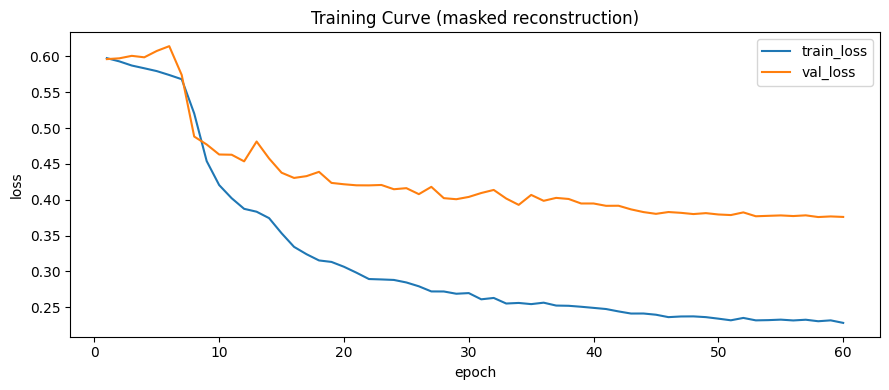

In [10]:
# =========================
# Curva de entrenamiento
# =========================
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(HIST['epoch'], HIST['train_loss'], label='train_loss')
if HIST['val_loss'].notna().any():
    ax.plot(HIST['epoch'], HIST['val_loss'], label='val_loss')
ax.set_title('Training Curve (masked reconstruction)')
ax.set_xlabel('epoch')
ax.set_ylabel('loss')
ax.legend()
plt.tight_layout()
plt.show()


In [11]:
# =========================
# Extraccion de embeddings fijos
# =========================
model.eval()

X_t = torch.from_numpy(X).float().to(DEVICE)
M_t = torch.from_numpy(M).bool().to(DEVICE)

bs = 256
z_all = []
with torch.no_grad():
    for i in range(0, len(X_t), bs):
        xb = X_t[i:i+bs]
        mb = M_t[i:i+bs]
        z, _ = model(xb, mb)
        z_all.append(z.detach().cpu().numpy())

Z = np.vstack(z_all).astype(np.float32)
print('Z shape =', Z.shape)

emb_cols = [f'emb_{i:03d}' for i in range(Z.shape[1])]
EMB = pd.DataFrame(Z, columns=emb_cols)
EMB.insert(0, 'global_segment_id', DF['global_segment_id'].to_numpy())
EMB['segment_origin'] = DF['segment_origin'].to_numpy()
EMB['source_name'] = DF['source_name'].to_numpy()
EMB['split'] = DF['split'].to_numpy()
EMB['start_ts'] = DF['start_ts'].to_numpy()
EMB['length'] = DF['length'].to_numpy()

EMB.to_parquet(EMB_PARQUET, index=False)
EMB.to_csv(EMB_CSV, index=False)

np.savez_compressed(
    PADDED_NPZ,
    X=X,
    mask=M.astype(np.uint8),
    lengths=L,
    embeddings=Z,
    global_segment_id=DF['global_segment_id'].to_numpy(dtype='U64'),
    split=DF['split'].to_numpy(dtype='U8'),
)

print('saved:')
print(' -', EMB_PARQUET)
print(' -', EMB_CSV)
print(' -', PADDED_NPZ)


Z shape = (991, 48)
saved:
 - ./phases/phase03_segment_analysis/output_attention_v2/USDJPY_segments_attention_embeddings.parquet
 - ./phases/phase03_segment_analysis/output_attention_v2/USDJPY_segments_attention_embeddings.csv
 - ./phases/phase03_segment_analysis/output_attention_v2/USDJPY_segments_padded_attention.npz


embedding norm stats:
count    991.000000
mean       8.782395
std        1.997283
min        3.504766
25%        7.737189
50%        8.823916
75%        9.827979
max       15.176657


,split,count,mean,std,min,max
0,test,149,7.782821,1.456930,3.580530,9.898850
1,train,695,9.222875,1.976155,3.704788,15.176657
2,val,147,7.713034,1.800067,3.504766,11.402193


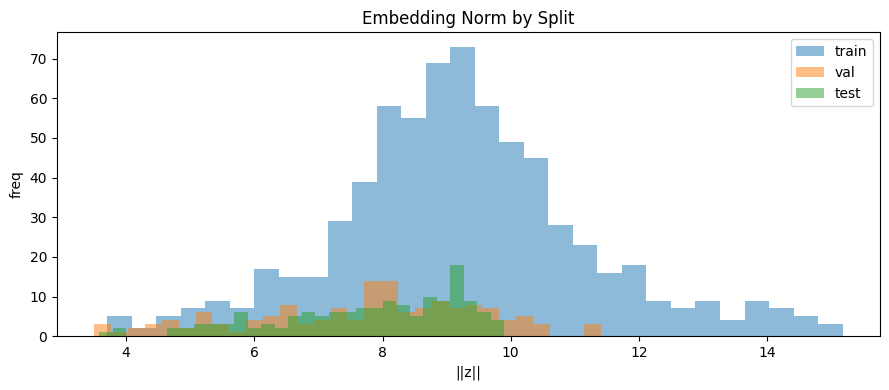

In [12]:
# =========================
# Diagnostico rapido de embeddings
# =========================
emb_norm = np.linalg.norm(Z, axis=1)
TMP = EMB[['split', 'segment_origin']].copy()
TMP['emb_norm'] = emb_norm

print('embedding norm stats:')
print(TMP['emb_norm'].describe().to_string())

display(
    TMP.groupby('split', dropna=False)['emb_norm']
    .agg(['count', 'mean', 'std', 'min', 'max'])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 4))
for sp in ['train', 'val', 'test']:
    s = TMP.loc[TMP['split'] == sp, 'emb_norm']
    if len(s) == 0:
        continue
    ax.hist(s, bins=30, alpha=0.5, label=sp)
ax.set_title('Embedding Norm by Split')
ax.set_xlabel('||z||')
ax.set_ylabel('freq')
ax.legend()
plt.tight_layout()
plt.show()


## Notas

- Este notebook implementa exactamente el flujo solicitado: **padding + attention mask + vector fijo**.
- El embedding fijo es el bottleneck (`EMB_DIM`) del encoder con atencion.
- Para clustering o clasificacion posterior, usar `USDJPY_segments_attention_embeddings.parquet`.
